|<h2>Course:</h2>|<h1><a href="https://udemy.com/course/dullms_x/?couponCode=202508" target="_blank">A deep understanding of AI language model mechanisms</a></h1>|
|-|:-:|
|<h2>Part 1:</h2>|<h1>Tokenizations and embeddings<h1>|
|<h2>Section:</h2>|<h1>Embedding spaces<h1>|
|<h2>Lecture:</h2>|<h1><b>CodeChallenge HELPER: GPT2 cosine similarities<b></h1>|

<br>

<h5><b>Teacher:</b> Mike X Cohen, <a href="https://sincxpress.com" target="_blank">sincxpress.com</a></h5>
<h5><b>Course URL:</b> <a href="https://udemy.com/course/dullms_x/?couponCode=202508" target="_blank">udemy.com/course/dullms_x/?couponCode=202508</a></h5>
<i>Using the code without the course may lead to confusion or errors.</i>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

# Import GPT-2 model and extract its embedding matrix

In [2]:
from transformers import GPT2Model,GPT2Tokenizer

# pretrained GPT-2 model and tokenizer
gpt2 = GPT2Model.from_pretrained('gpt2')
tokenizer = GPT2Tokenizer.from_pretrained('gpt2')

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [3]:
# get the Word Token Embeddings matrix
embeddings = gpt2.get_input_embeddings().weight.detach().numpy()

# Exercise 1: The cosmic banana

In [4]:
# words of interest
word1 = 'banana'
word2 = 'apple'
word3 = 'cosmic'

# decomposition
for w in [word1,word2,word3]:
  t = tokenizer.encode(w)
  print(f'"{w}" comprises {len(t)} tokens:\n   {t}\n')

"banana" comprises 2 tokens:
   [3820, 2271]

"apple" comprises 1 tokens:
   [18040]

"cosmic" comprises 2 tokens:
   [6966, 9383]



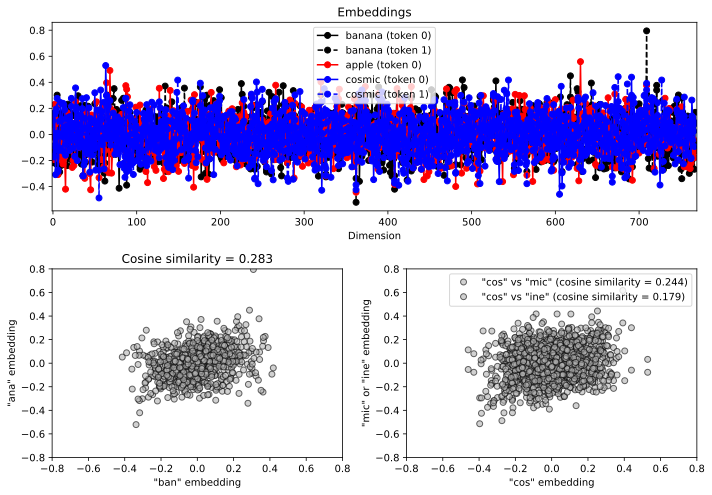

In [5]:
# setup the figure subplot geometry
fig = plt.figure(figsize=(10,7))
gs = GridSpec(2,2)
ax0 = fig.add_subplot(gs[0,:])
ax1 = fig.add_subplot(gs[1,0])
ax2 = fig.add_subplot(gs[1,1])


# plot the embeddings by dimension
colors = 'krb'
linestyles = ['-','--','-.',':']
for idx,word in enumerate([word1,word2,word3]):
  wordidx = tokenizer.encode(word)
  for j in range(len(wordidx)):
    ax0.plot(embeddings[wordidx[j]], label=f'{word} (token {j})', marker='o', linestyle=linestyles[j], color=colors[idx])

ax0.set(xlabel='Dimension',title='Embeddings',xlim=[-1,embeddings.shape[1]+1])
ax0.legend()



# cosine similarity between 'ban' and 'ana'
v1 = embeddings[tokenizer.encode('ban')]
v2 = embeddings[tokenizer.encode('ana')]
cossim = (v1*v2).sum()/(np.linalg.norm(v1)*np.linalg.norm(v2))

# plot the embeddings by each other
ax1.plot(v1,v2,'ko',markerfacecolor=[.7,.7,.7,.6])
ax1.set(xlim=[-.8,.8],ylim=[-.8,.8],xlabel='"ban" embedding',ylabel='"ana" embedding',
        title=f'Cosine similarity = {cossim:.3f}')



# plot the "cos" for two endings
for s in ['mic','ine']:

  # cosine similarity
  v1 = embeddings[tokenizer.encode('cos')].squeeze()
  v2 = embeddings[tokenizer.encode(s)].squeeze()
  cossim = (v1*v2).sum()/(np.linalg.norm(v1)*np.linalg.norm(v2))

  # plot
  ax2.plot(v1,v2,'ko',markerfacecolor=[.7,.7,.7,.6],label=f'"cos" vs "{s}" (cosine similarity = {cossim:.3f})')

ax2.legend(fontsize=10)
ax2.set(xlim=[-.8,.8],ylim=[-.8,.8],xlabel='"cos" embedding',ylabel='"mic" or "ine" embedding')


# final touches
plt.tight_layout()
plt.show()

# Exercise 2: Find tokens with similar embeddings

In [6]:
# get seed index and embedding vector
seed = tokenizer.encode(' gay')
seedvect = embeddings[seed].squeeze()
seedvectNorm = np.linalg.norm(seedvect)

# calculate cosine similarity to all other tokens in a for-loop
cossims = np.zeros(len(embeddings))
for idx,v in enumerate(embeddings):
  cossims[idx] = (seedvect*v).sum()/(seedvectNorm * np.linalg.norm(v))

# and visualize
plt.figure(figsize=(10,4))
plt.plot(cossims,'k.',alpha=.6,markerfacecolor='w')
plt.gca().set(xlim=[-5,len(cossims)+5],xlabel='Token index',ylabel='Cosine similarity',
              title='Cosine similarity to " gay"')


# top 20 largest cosine-similarities
top20 = np.argsort(cossims)[-20:]
for i in top20:
  plt.plot(i, cossims[i], 'ro', alpha=.8, markerfacecolor='r')



plt.show()

In [7]:
# tokens closest to "Mike"
for n in top20[::-1]:
  print(f'"{tokenizer.decode([n])}" with cosine similarity {cossims[n]:.3f}')

" gay" with cosine similarity 1.000
" LGBT" with cosine similarity 0.762
" gays" with cosine similarity 0.757
" homosexual" with cosine similarity 0.748
"gay" with cosine similarity 0.732
"Gay" with cosine similarity 0.730
" Gay" with cosine similarity 0.725
" homosexuals" with cosine similarity 0.693
" homosexuality" with cosine similarity 0.680
" lesbian" with cosine similarity 0.677
" queer" with cosine similarity 0.658
" LGBTQ" with cosine similarity 0.652
" homophobic" with cosine similarity 0.637
" heterosexual" with cosine similarity 0.636
" transgender" with cosine similarity 0.635
" homophobia" with cosine similarity 0.628
" bisexual" with cosine similarity 0.619
" lesbians" with cosine similarity 0.605
"LGBT" with cosine similarity 0.605
" sexuality" with cosine similarity 0.572


# Exercise 3: One-to-all cosine similarity via linear algebra

In [10]:
# normalize entire embedding matrix (in a new variable!)
Enorm = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)

print(f'Enorm shape = {Enorm.shape}')
# cosine similarity matrices
cossims2 = Enorm[seed] @ Enorm.T

Enorm shape = (50257, 768)


In [11]:
print(f'Size of for-loop version:   {cossims.shape}')
print(f'Size of vectorized version: {cossims2.shape}')

# remove singleton dimension
cossims2 = cossims2.squeeze()

# inspect again
print('\n** After squeezing:')
print(f'Size of for-loop version:   {cossims.shape}')
print(f'Size of vectorized version: {cossims2.shape}')

Size of for-loop version:   (50257,)
Size of vectorized version: (1, 50257)

** After squeezing:
Size of for-loop version:   (50257,)
Size of vectorized version: (50257,)


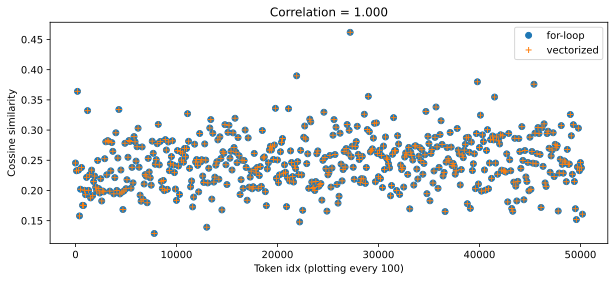

In [12]:
plt.figure(figsize=(10,4))
plt.plot(range(0,len(cossims),100),cossims[::100],'o',label='for-loop')
plt.plot(range(0,len(cossims),100),cossims2[::100],'+',label='vectorized')

plt.legend()
plt.gca().set(xlabel='Token idx (plotting every 100)',ylabel='Cossine similarity',title=f'Correlation = {np.corrcoef(cossims,cossims2)[0,1]:.3f}')
plt.show()